# Notebook 01: Can a linear probe read truth from Gemma's hidden states?

**Goal.** Before building a lie detector, I need to know if Gemma 2 2B-it stores "this statement is true" in a way that a simple linear model can read. If it does, I can use that signal as a polygraph for the model's own answers.

**Questions**
1. Can a logistic regression trained on hidden states separate true from false statements, and at which layer?
2. Is it better than simply asking Gemma "true or false?"
3. Does it still work on topics and phrasings it never saw during training?

**What I do**
1. Load about 7,700 labelled statements from *The Geometry of Truth* (Marks and Tegmark, 2023).
2. Run every statement through Gemma and keep the hidden state at the last token, at all 26 layers.
3. Train one probe per layer and compare it with three baselines.
4. Test generalization with a leave-one-dataset-out test and a "not" test.

This is my first pass. The layer here is picked on the same split it is scored on, so the number is a bit optimistic. Notebook 01b repeats the evaluation with a stricter protocol, and that is the number I report.

**Outputs** (saved to Google Drive): `statements.csv`, `polygraph_probe.npz`, `results_layers.csv`, `results_lodo.csv`, `results_negation.csv`, `results_per_dataset.csv`, `summary.json` and the working figures.

**How to run.** Google Colab with an A100 GPU, about 25 to 40 minutes. Accept the Gemma license on Hugging Face, add a read token as the Colab secret `HF_TOKEN`, then *Runtime > Run all*.

## 0. Configuration
All settings are in the next cell. Every result in this repository uses these defaults.

In [1]:
# ============================== CONFIG ==============================
MODEL_ID          = "google/gemma-2-2b-it"
FORMATS           = ["assistant", "raw"]     # where the statement sits (explained in section 2)
MAIN_FORMAT       = "assistant"              # the format the polygraph will use in notebook 02
MAX_PER_DATASET   = 1000                     # balanced cap per dataset (keeps runs fast)
TEST_FRACTION     = 0.2
BATCH_SIZE        = 32                       # lower it if the GPU runs out of memory
PROBE_LAYER_STRIDE = 1                       # probe every layer
LODO_LAYER_STRIDE  = 2                       # leave-one-dataset-out every N layers (+ best layer)
SEED              = 0
SAVE_TO_DRIVE     = True                     # results/figures persist in Google Drive
# ====================================================================

In [2]:
!pip -q install -U "transformers>=4.44" accelerate scikit-learn matplotlib pandas

In [3]:
import os, json, time, random, subprocess, hashlib, pathlib
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED)

MODEL_SHORT = MODEL_ID.split("/")[-1]
IN_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in globals() else False

if SAVE_TO_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = pathlib.Path("/content/drive/MyDrive/ai-polygraph") / MODEL_SHORT
else:
    OUT = pathlib.Path("outputs") / MODEL_SHORT
ACTS_DIR = pathlib.Path("/content/acts" if IN_COLAB else "acts") / MODEL_SHORT   # large files stay local
FIG = OUT / "figures"
for p in (OUT, FIG, ACTS_DIR):
    p.mkdir(parents=True, exist_ok=True)
print("Results ->", OUT.resolve())

Mounted at /content/drive
Results -> /content/drive/MyDrive/ai-polygraph/gemma-2-2b-it


## 1. Data: statements with known labels
I use the curated datasets from *The Geometry of Truth* (Marks and Tegmark, 2023), downloaded from a fixed commit so the data cannot change. Each dataset is capped and balanced (50% true, 50% false).

| Dataset | Example | Topic |
|---|---|---|
| `cities` | "The city of Krasnodar is in Russia." | geography |
| `neg_cities` | "The city of Krasnodar is **not** in Russia." | geography, negated |
| `sp_en_trans` | "The Spanish word 'uno' means 'one'." | translation |
| `neg_sp_en_trans` | "The Spanish word 'uno' does **not** mean 'one'." | translation, negated |
| `larger_than`, `smaller_than` | "Fifty-one is larger than fifty-two." | numbers |
| `companies_true_false` | "Thermo Fisher ... semiconductor products." | business |
| `counterfact_true_false` | "The mother tongue of Danielle Darrieux is French." | world knowledge |
| `common_claim_true_false` | "Spiders can use surface tension to walk on water." | common claims (noisier labels) |

In [4]:
GOT_REPO   = "https://github.com/saprmarks/geometry-of-truth.git"
GOT_COMMIT = "5d1c630c44f7e50bda7ad86d601ccadf9abc5ddb"
GOT_DIR    = pathlib.Path(globals().get("GOT_DIR", "geometry-of-truth"))
if not GOT_DIR.exists():
    subprocess.run(["git", "clone", "-q", GOT_REPO, str(GOT_DIR)], check=True)
    subprocess.run(["git", "-C", str(GOT_DIR), "checkout", "-q", GOT_COMMIT], check=True)

DATASETS = {   # name: (topic, negated)
    "cities":                  ("geography",   False),
    "neg_cities":              ("geography",   True),
    "sp_en_trans":             ("translation", False),
    "neg_sp_en_trans":         ("translation", True),
    "larger_than":             ("numbers",     False),
    "smaller_than":            ("numbers",     False),
    "companies_true_false":    ("business",    False),
    "counterfact_true_false":  ("knowledge",   False),
    "common_claim_true_false": ("claims",      False),
}

def load_statements(max_per_dataset=MAX_PER_DATASET, seed=SEED):
    frames = []
    for name, (topic, negated) in DATASETS.items():
        d = pd.read_csv(GOT_DIR / "datasets" / f"{name}.csv")[["statement", "label"]]
        d = d.dropna().drop_duplicates("statement")
        d["label"] = d["label"].astype(int)
        n_per_class = min(max_per_dataset // 2, d["label"].value_counts().min())
        d = pd.concat([d[d.label == c].sample(n_per_class, random_state=seed) for c in (0, 1)])
        d["dataset"], d["topic"], d["negated"] = name, topic, negated
        frames.append(d)
    df = pd.concat(frames, ignore_index=True)
    # stratified train/test split inside every dataset x label cell
    rng = np.random.default_rng(seed)
    df["split"] = "train"
    for _, idx in df.groupby(["dataset", "label"]).groups.items():
        idx = np.array(list(idx)); rng.shuffle(idx)
        df.loc[idx[: int(round(len(idx) * TEST_FRACTION))], "split"] = "test"
    return df.reset_index(drop=True)

df = load_statements()
print(f"{len(df):,} statements")
display(df.groupby(["dataset", "label"]).size().unstack().assign(test=df[df.split=="test"].groupby("dataset").size()))

7,696 statements


label,0,1,test
dataset,,,
cities,500,500,200
common_claim_true_false,500,500,200
companies_true_false,500,500,200
counterfact_true_false,500,500,200
larger_than,500,500,200
neg_cities,500,500,200
neg_sp_en_trans,174,174,70
smaller_than,500,500,200
sp_en_trans,174,174,70


## 2. Model and hidden states
I read the residual stream at the last token of each statement (the final period), at every layer.

I use two formats:
- `assistant`: Gemma says the statement in a chat turn (`user: Tell me one fact.` then `model: <statement>`). This is the main format, because later I want to read Gemma's own answers.
- `raw`: the bare statement, as in the original paper. I keep it only as a comparison.

In [5]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

if IN_COLAB:
    try:
        from google.colab import userdata
        from huggingface_hub import login
        login(token=userdata.get("HF_TOKEN"))
    except Exception as e:
        print("HF login skipped:", e)

assert torch.cuda.is_available(), "Switch the runtime to a GPU (A100 / L4)."
print(torch.cuda.get_device_name(0))

tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = "left"          # so position -1 is always the last real token
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=torch.bfloat16, device_map="cuda", attn_implementation="eager")
model.eval()
N_LAYERS, D_MODEL = model.config.num_hidden_layers, model.config.hidden_size
LAYERS = list(range(N_LAYERS + 1))   # 0 = embeddings, N_LAYERS = last block
print(f"{MODEL_SHORT}: {N_LAYERS} layers, d_model={D_MODEL}")

HF login skipped: Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.
NVIDIA A100-SXM4-80GB


config.json:   0%|          | 0.00/838 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/47.0k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/288 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/187 [00:00<?, ?B/s]

gemma-2-2b-it: 26 layers, d_model=2304


In [6]:
CHAT_PREFIX = tok.apply_chat_template(
    [{"role": "user", "content": "Tell me one fact."}], tokenize=False, add_generation_prompt=True)

def build_text(statement, fmt):
    if fmt == "assistant":
        return CHAT_PREFIX + statement
    if fmt == "raw":
        return tok.bos_token + statement
    raise ValueError(fmt)

ex = build_text(df.statement[0], "assistant")
print(repr(ex))
ids = tok(ex, add_special_tokens=False).input_ids
print("last token read by the probe:", repr(tok.decode(ids[-1])))

'<bos><start_of_turn>user\nTell me one fact.<end_of_turn>\n<start_of_turn>model\nThe city of Jeonju is in the United States.'
last token read by the probe: '.'


In [8]:
@torch.no_grad()
def extract_acts(texts, path, batch_size=BATCH_SIZE):
    # Residual stream at the last token, every layer -> float32 memmap [layers, N, d_model]
    key = hashlib.md5(("\n".join(texts) + MODEL_ID).encode()).hexdigest()[:10]
    path = pathlib.Path(f"{path}_{key}.npy")
    if path.exists():
        print("cached:", path.name)
        return np.load(path, mmap_mode="r")
    acts = np.lib.format.open_memmap(path.with_suffix(".tmp.npy"), mode="w+", dtype=np.float32,
                                     shape=(len(LAYERS), len(texts), D_MODEL))
    for i in tqdm(range(0, len(texts), batch_size), desc=path.name):
        enc = tok(texts[i:i + batch_size], return_tensors="pt", padding=True,
                  add_special_tokens=False).to("cuda")
        hs = model(**enc, output_hidden_states=True).hidden_states   # (n_layers+1) x [B, T, d]
        last = torch.stack([h[:, -1, :] for h in hs]).float().cpu().numpy()
        acts[:, i:i + last.shape[1]] = last
    acts.flush(); del acts
    path.with_suffix(".tmp.npy").rename(path)
    return np.load(path, mmap_mode="r")

ACTS = {}
t0 = time.time()
for fmt in FORMATS:
    ACTS[fmt] = extract_acts([build_text(s, fmt) for s in df.statement], ACTS_DIR / f"acts_{fmt}")
print(f"done in {(time.time()-t0)/60:.1f} min; shape {ACTS[FORMATS[0]].shape}")

acts_assistant_cf49e8fdf8.npy:   0%|          | 0/241 [00:00<?, ?it/s]

acts_raw_d18694ae48.npy:   0%|          | 0/241 [00:00<?, ?it/s]

done in 0.7 min; shape (27, 7696, 2304)


## 3. One probe per layer, against baselines
I compare four things. All of them are scored with AUROC on held-out statements (0.5 is a coin flip, 1.0 is perfect).
- **Logistic regression probe** on standardized activations. This is the polygraph.
- **Mass-mean probe**: the difference between the average true and the average false activation. It needs no training.
- **Shuffled-label control**: the same probe trained on random labels. If this scored well, the probe would be fitting noise.
- **Ask the model**: Gemma's own probability for "True" vs "False" when I ask it about the statement. The probe is only interesting if it is at least as good as this.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score

PROBE_C = 0.1   # L2 strength; a quick check on one layer is below

def fit_lr(X, y, C=None):
    sc = StandardScaler().fit(X)
    clf = LogisticRegression(C=C or PROBE_C, max_iter=2000, tol=1e-3).fit(sc.transform(X), y)
    return {"kind": "lr", "scaler": sc, "clf": clf}

def fit_mm(X, y):
    mu_t, mu_f = X[y == 1].mean(0), X[y == 0].mean(0)
    return {"kind": "mm", "dir": mu_t - mu_f, "mid": (mu_t + mu_f) / 2}

def score(probe, X):
    if probe["kind"] == "lr":
        return probe["clf"].decision_function(probe["scaler"].transform(X))
    return (X - probe["mid"]) @ probe["dir"]

def evaluate(s, y):
    return {"auroc": roc_auc_score(y, s), "acc": accuracy_score(y, (s > 0).astype(int))}

def layer_X(fmt, layer, mask=None):
    X = np.asarray(ACTS[fmt][layer], dtype=np.float32)
    return X if mask is None else X[mask]

tr = (df.split == "train").values; te = ~tr
y = df.label.values
rng = np.random.default_rng(SEED)

# quick regularization check on a middle layer (validation carved out of train)
mid = LAYERS[len(LAYERS) // 2]
Xm = layer_X(MAIN_FORMAT, mid, tr); ym = y[tr]
cut = int(0.8 * len(ym)); perm = rng.permutation(len(ym))
for C in (0.01, 0.1, 1.0):
    p = fit_lr(Xm[perm[:cut]], ym[perm[:cut]], C)
    print(f"C={C:<5} val AUROC={evaluate(score(p, Xm[perm[cut:]]), ym[perm[cut:]])['auroc']:.3f}")

C=0.01  val AUROC=0.982
C=0.1   val AUROC=0.976
C=1.0   val AUROC=0.971


In [10]:
rows = []
probe_layers = LAYERS[::PROBE_LAYER_STRIDE]
for fmt in FORMATS:
    for L in tqdm(probe_layers, desc=f"probes [{fmt}]"):
        Xtr, Xte = layer_X(fmt, L, tr), layer_X(fmt, L, te)
        methods = [("probe", fit_lr, y[tr]), ("mass-mean", fit_mm, y[tr])]
        if fmt == MAIN_FORMAT:   # the control only needs to run once
            methods.append(("shuffled control", fit_lr, rng.permutation(y[tr])))
        for method, fit, labels in methods:
            p = fit(Xtr, labels)
            rows.append({"format": fmt, "layer": L, "method": method, **evaluate(score(p, Xte), y[te])})
layer_res = pd.DataFrame(rows)

best = (layer_res[layer_res.method == "probe"].sort_values("auroc", ascending=False)
        .groupby("format").head(1).set_index("format"))
BEST_LAYER = int(best.loc[MAIN_FORMAT, "layer"])
display(best)
print(f"Best layer for the polygraph ({MAIN_FORMAT}): {BEST_LAYER}")

probes [assistant]:   0%|          | 0/27 [00:00<?, ?it/s]

probes [raw]:   0%|          | 0/27 [00:00<?, ?it/s]

,layer,method,auroc,acc
format,,,,
assistant,14,probe,0.980636,0.931818
raw,15,probe,0.977172,0.922727


Best layer for the polygraph (assistant): 14


**Result.** The truth signal becomes readable in the middle of the network. The best layer is 14 (AUROC 0.981 in the `assistant` format, 0.977 for raw statements). The shuffled-label control stays at chance, so the probe is not just fitting noise. I use layer 14 from now on.

In [11]:
@torch.no_grad()
def ask_model_scores(statements, batch_size=BATCH_SIZE):
    # Baseline: logit(True) - logit(False) when the model is asked directly
    t_id = tok.encode("True", add_special_tokens=False); f_id = tok.encode("False", add_special_tokens=False)
    if len(t_id) != 1 or len(f_id) != 1:
        print("note: True/False are multi-token here; using their first token", t_id, f_id)
    prompts = [tok.apply_chat_template(
        [{"role": "user", "content": "Is the following statement true or false? "
                                      "Answer with exactly one word: True or False.\n\nStatement: " + s}],
        tokenize=False, add_generation_prompt=True) for s in statements]
    out = []
    for i in tqdm(range(0, len(prompts), batch_size), desc="ask the model"):
        enc = tok(prompts[i:i + batch_size], return_tensors="pt", padding=True, add_special_tokens=False).to("cuda")
        logits = model(**enc).logits[:, -1, :].float()
        out.append((logits[:, t_id[0]] - logits[:, f_id[0]]).cpu().numpy())
    return np.concatenate(out)

ask_scores = ask_model_scores(df.statement[te].tolist())
ASK = evaluate(ask_scores, y[te])
print("Just ask the model:", {k: round(v, 3) for k, v in ASK.items()})

ask the model:   0%|          | 0/49 [00:00<?, ?it/s]

Just ask the model: {'auroc': 0.94, 'acc': 0.868}


**Result.** Asking Gemma directly gives AUROC 0.940 on the same statements, a bit lower than the probe when all datasets are pooled. Notebook 01b compares the two dataset by dataset, where they turn out to be very close.

In [12]:
# Per-dataset accuracy of the polygraph at its best layer (held-out statements)
polygraph = fit_lr(layer_X(MAIN_FORMAT, BEST_LAYER, tr), y[tr])
s_te = score(polygraph, layer_X(MAIN_FORMAT, BEST_LAYER, te))
per_ds = []
for name in DATASETS:
    m = (df.dataset[te] == name).values
    per_ds.append({"dataset": name, "polygraph_auroc": roc_auc_score(y[te][m], s_te[m]),
                   "polygraph_acc": accuracy_score(y[te][m], (s_te[m] > 0).astype(int))}
                  | ({"ask_model_auroc": roc_auc_score(y[te][m], ask_scores[m])} if "ask_scores" in globals() else {}))
per_ds = pd.DataFrame(per_ds).round(3)
display(per_ds)

,dataset,polygraph_auroc,polygraph_acc,ask_model_auroc
0,cities,1.000,1.000,1.000
1,neg_cities,1.000,0.995,1.000
2,sp_en_trans,0.998,0.986,1.000
3,neg_sp_en_trans,1.000,0.986,1.000
4,larger_than,1.000,1.000,1.000
5,smaller_than,1.000,1.000,0.904
6,companies_true_false,0.973,0.935,0.923
7,counterfact_true_false,0.878,0.790,0.841
8,common_claim_true_false,0.844,0.765,0.847


The probe is perfect or near perfect on cities, translations and numbers. It is weaker on `counterfact` and `common_claim` (0.84 to 0.88), which are harder and have noisier labels. Asking the model has the same weak spots.

## 4. Does the probe generalize?
1. **Leave one dataset out.** I train on all datasets except one and test on the one left out. A probe that only learned "facts about cities" would fail here.
2. **The "not" test.** I train only on affirmative statements (`cities`, `sp_en_trans`) and test on their negated versions. If the probe learned "this sounds like a normal fact" instead of truth, the word *not* will flip its answer. This is my first check for a shortcut.

In [13]:
lodo_layers = sorted(set(LAYERS[::LODO_LAYER_STRIDE]) | {BEST_LAYER})
lodo = []
ds = df.dataset.values
for L in tqdm(lodo_layers, desc="leave-one-dataset-out"):
    X = layer_X(MAIN_FORMAT, L)
    for name in DATASETS:
        out = ds == name
        p = fit_lr(X[~out], y[~out])
        lodo.append({"layer": L, "held_out": name, **evaluate(score(p, X[out]), y[out])})
lodo = pd.DataFrame(lodo)
display(lodo[lodo.layer == BEST_LAYER].round(3))

leave-one-dataset-out:   0%|          | 0/14 [00:00<?, ?it/s]

,layer,held_out,auroc,acc
63,14,cities,1.000,0.995
64,14,neg_cities,1.000,0.963
65,14,sp_en_trans,0.883,0.830
66,14,neg_sp_en_trans,0.365,0.486
67,14,larger_than,0.862,0.604
68,14,smaller_than,0.479,0.479
69,14,companies_true_false,0.926,0.851
70,14,counterfact_true_false,0.840,0.751
71,14,common_claim_true_false,0.713,0.647


**Result.** Generalization is uneven. Cities transfer perfectly, but some datasets are much harder when the probe never saw anything like them: `smaller_than` drops to 0.48 and `neg_sp_en_trans` to 0.37 (below chance, so the probe reads them backwards). This tells me that one probe can work very well on familiar data and still fail on a new kind of sentence.

In [14]:
X = layer_X(MAIN_FORMAT, BEST_LAYER)
neg_rows = []
for aff, neg in [("cities", "neg_cities"), ("sp_en_trans", "neg_sp_en_trans")]:
    m_aff, m_neg = ds == aff, ds == neg
    p_aff = fit_lr(X[m_aff], y[m_aff])                                   # never saw "not"
    p_in  = fit_lr(X[m_neg & tr], y[m_neg & tr])                         # trained on negations
    p_all = fit_lr(X[tr & ~m_neg], y[tr & ~m_neg])                       # everything except this negated set
    neg_rows += [
        {"test_set": neg, "condition": "no_not",  "trained_on": f"{aff} only (never saw 'not')", **evaluate(score(p_aff, X[m_neg & te]), y[m_neg & te])},
        {"test_set": neg, "condition": "others",  "trained_on": "all other datasets",            **evaluate(score(p_all, X[m_neg & te]), y[m_neg & te])},
        {"test_set": neg, "condition": "in_dist", "trained_on": f"{neg} itself (upper bound)",    **evaluate(score(p_in, X[m_neg & te]), y[m_neg & te])},
    ]
neg_res = pd.DataFrame(neg_rows)
display(neg_res.round(3))

,test_set,condition,trained_on,auroc,acc
0,neg_cities,no_not,cities only (never saw 'not'),0.885,0.805
1,neg_cities,others,all other datasets,0.999,0.935
2,neg_cities,in_dist,neg_cities itself (upper bound),1.000,0.995
3,neg_sp_en_trans,no_not,sp_en_trans only (never saw 'not'),0.000,0.314
4,neg_sp_en_trans,others,all other datasets,0.404,0.486
5,neg_sp_en_trans,in_dist,neg_sp_en_trans itself (upper bound),1.000,1.000


**Result.** This is the most surprising finding of the notebook. A probe trained only on affirmative translations scores **AUROC 0.00** on the negated translations: it is perfectly wrong. For cities the same test gives 0.885. A probe trained on negated translations scores 1.00, but a probe trained on all the other datasets (negated cities included) still only reaches 0.40. Negations of each kind need to be in the training data.

So a probe can look excellent on normal statements and still read "sounds like a correct translation" instead of truth. I check this properly in notebook 01b, and the final polygraph is always trained with negations included.

## 5. Figures
I save every figure as PNG (300 dpi) and SVG. The final poster figures are made later from the saved results with `scripts/make_figures.py`.

In [15]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#9b9a94"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIVERGE = LinearSegmentedColormap.from_list("div", ["#a8431c", "#eb6834", "#f4b394", "#ecebe7", "#86b6ef", "#2a78d6", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.size": 12, "axes.titlesize": 15, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "legend.frameon": False, "text.color": INK,
})

def save(fig, name):
    for ext in ("png", "svg"):
        fig.savefig(FIG / f"{name}.{ext}", dpi=300, bbox_inches="tight")
    plt.show()

def subtitle(ax, text, y=1.02):
    ax.text(0, y, text, transform=ax.transAxes, fontsize=11, color=INK2, va="bottom")

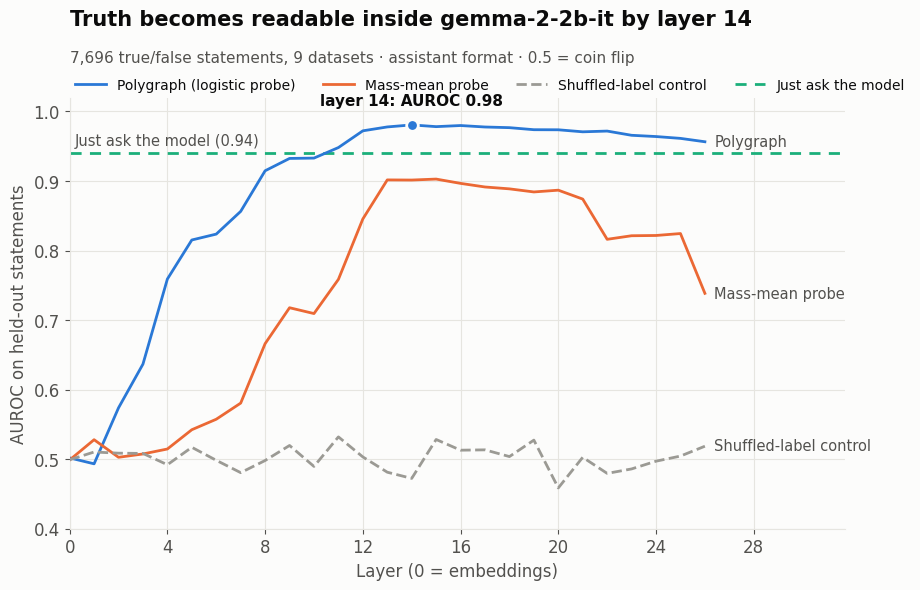

In [18]:
# Figure 1: Brain scan: where does truth become readable?
d = layer_res[layer_res.format == MAIN_FORMAT]
fig, ax = plt.subplots(figsize=(10, 5.6))
series = [("probe", "Polygraph (logistic probe)", BLUE, "-"),
          ("mass-mean", "Mass-mean probe", ORANGE, "-"),
          ("shuffled control", "Shuffled-label control", GRAY, "--")]
for method, label, color, ls in series:
    s = d[d.method == method].sort_values("layer")
    ax.plot(s.layer, s.auroc, color=color, lw=2, ls=ls, label=label, zorder=3)
    ax.text(s.layer.iloc[-1] + max(LAYERS) * 0.015, s.auroc.iloc[-1], label.split(" (")[0], color=INK2, fontsize=10.5, va="center")
if "ASK" in globals():
    ax.axhline(ASK["auroc"], color=AQUA, lw=2, ls=(0, (4, 3)), label="Just ask the model", zorder=2)
    ax.text(0.2, ASK["auroc"] + 0.012, f"Just ask the model ({ASK['auroc']:.2f})", color=INK2, fontsize=10.5)
b = d[(d.method == "probe") & (d.layer == BEST_LAYER)].iloc[0]
ax.scatter([BEST_LAYER], [b.auroc], s=70, color=BLUE, edgecolor=SURF, linewidth=2, zorder=4)
ax.annotate(f"layer {BEST_LAYER}: AUROC {b.auroc:.2f}", (BEST_LAYER, b.auroc), xytext=(0, 14),
            textcoords="offset points", ha="center", fontsize=11, color=INK, weight="semibold")
from matplotlib.ticker import MaxNLocator
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set(xlim=(0, max(LAYERS) * 1.22), ylim=(0.4, 1.02), xlabel="Layer (0 = embeddings)", ylabel="AUROC on held-out statements")
ax.set_title(f"Truth becomes readable inside {MODEL_SHORT} by layer {BEST_LAYER}", pad=52)
subtitle(ax, f"{len(df):,} true/false statements, 9 datasets · {MAIN_FORMAT} format · 0.5 = coin flip", y=1.075)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4, fontsize=10, handlelength=2.2, borderaxespad=0)
save(fig, "fig1_brain_scan")

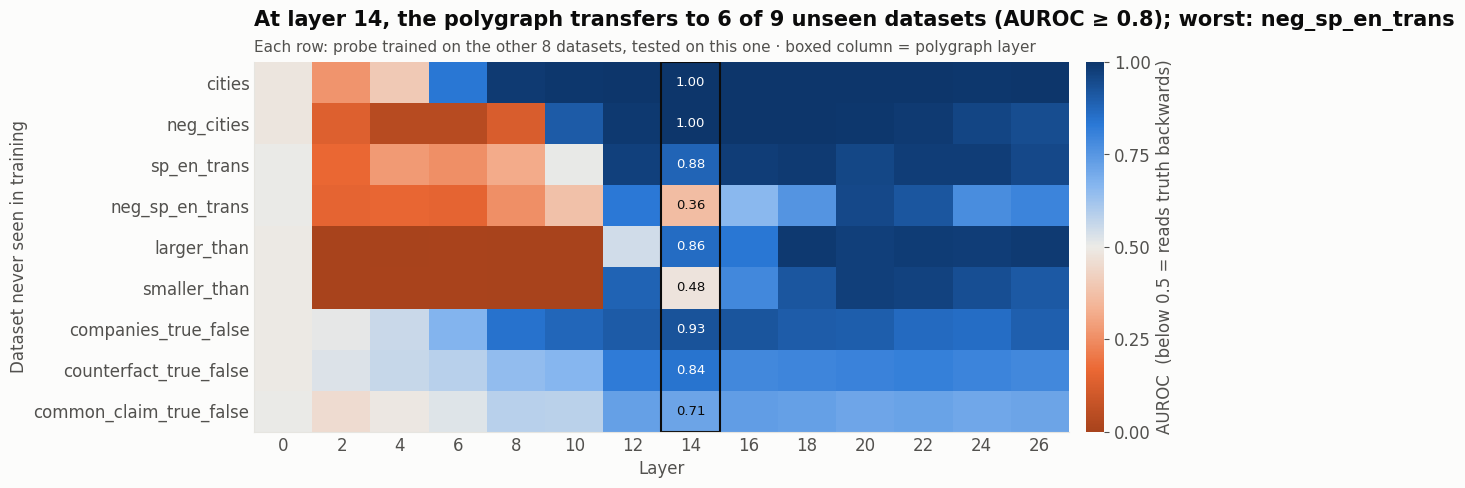

In [19]:
# Figure 2: Generalization: leave one dataset out
piv = lodo.pivot(index="held_out", columns="layer", values="auroc").loc[list(DATASETS)]
fig, ax = plt.subplots(figsize=(11, 4.8))
im = ax.imshow(piv.values, cmap=DIVERGE, vmin=0.0, vmax=1.0, aspect="auto")
ax.set_xticks(range(len(piv.columns)), piv.columns); ax.set_yticks(range(len(piv.index)), piv.index)
ax.grid(False); ax.tick_params(length=0)
bi = list(piv.columns).index(BEST_LAYER)
ax.add_patch(plt.Rectangle((bi - 0.5, -0.5), 1, len(piv.index), fill=False, ec=INK, lw=1.5))
for j, name in enumerate(piv.index):
    v = piv.iloc[j, bi]
    ax.text(bi, j, f"{v:.2f}", ha="center", va="center", fontsize=9.5, color="white" if abs(v - 0.5) > 0.32 else INK)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, ticks=[0, 0.25, 0.5, 0.75, 1])
cb.set_label("AUROC  (below 0.5 = reads truth backwards)", color=INK2); cb.outline.set_visible(False)
ax.set_xlabel("Layer"); ax.set_ylabel("Dataset never seen in training")
n_ok = int((piv[BEST_LAYER] >= 0.8).sum()); worst = piv[BEST_LAYER].idxmin()
ax.set_title(f"At layer {BEST_LAYER}, the polygraph transfers to {n_ok} of {len(piv)} unseen datasets (AUROC ≥ 0.8); worst: {worst}", pad=26)
subtitle(ax, "Each row: probe trained on the other 8 datasets, tested on this one · boxed column = polygraph layer")
save(fig, "fig2_generalization")

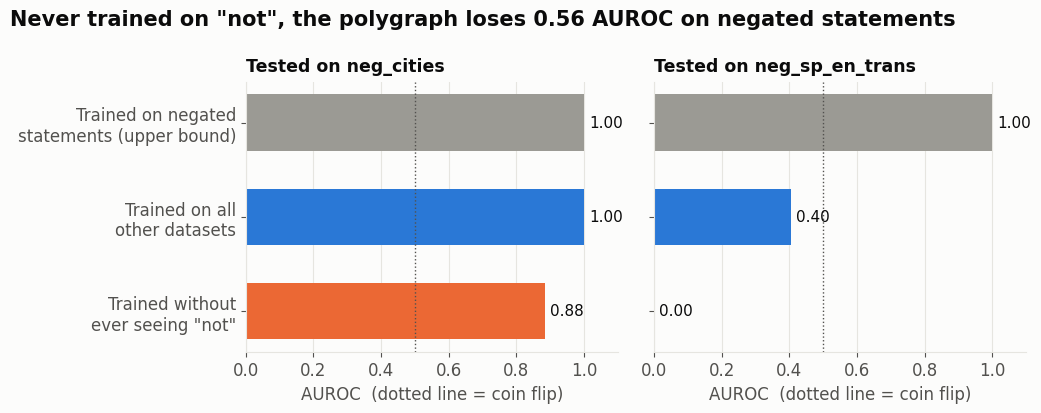

In [20]:
# Figure 3: The "not" test
COND = [("in_dist", "Trained on negated\nstatements (upper bound)", GRAY),
        ("others",  "Trained on all\nother datasets", BLUE),
        ("no_not",  "Trained without\never seeing \"not\"", ORANGE)]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for k, (ax, (test_set, g)) in enumerate(zip(axes, neg_res.groupby("test_set", sort=False))):
    g = g.set_index("condition")
    vals = [g.loc[c, "auroc"] for c, _, _ in COND]
    ax.barh(range(len(COND)), vals, color=[c for _, _, c in COND], height=0.6)
    for i, v in enumerate(vals):
        ax.text(v + 0.015, i, f"{v:.2f}", va="center", fontsize=11, color=INK)
    ax.set_yticks(range(len(COND)), [lab for _, lab, _ in COND] if k == 0 else [""] * len(COND))
    ax.axvline(0.5, color=INK2, lw=1, ls=":")
    ax.set_axisbelow(True)
    ax.set_xlim(0, 1.1); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    ax.set_title(f"Tested on {test_set}", fontsize=12.5, pad=8); ax.set_xlabel("AUROC  (dotted line = coin flip)")
drop = (neg_res.query("condition=='in_dist'").auroc.mean() - neg_res.query("condition=='no_not'").auroc.mean())
headline = (f"Never trained on \"not\", the polygraph loses {drop:.2f} AUROC on negated statements" if drop > 0.05
            else "The polygraph survives the word \"not\" even without negated training data")
fig.suptitle(headline, x=0.01, ha="left", fontsize=15, weight="semibold")
fig.tight_layout()
save(fig, "fig3_negation")

## 6. Save the probe and the numbers
`polygraph_probe.npz` is the trained probe that notebook 02 puts under stress.

In [21]:
X = layer_X(MAIN_FORMAT, BEST_LAYER)
final = fit_lr(X[tr], y[tr])                 # same split as reported above
mm = fit_mm(X[tr], y[tr])
np.savez(OUT / "polygraph_probe.npz",
         layer=BEST_LAYER, format=MAIN_FORMAT, model=MODEL_ID,
         scaler_mean=final["scaler"].mean_, scaler_scale=final["scaler"].scale_,
         coef=final["clf"].coef_[0], intercept=final["clf"].intercept_,
         massmean_dir=mm["dir"], massmean_mid=mm["mid"])
layer_res.to_csv(OUT / "results_layers.csv", index=False)
lodo.to_csv(OUT / "results_lodo.csv", index=False)
neg_res.to_csv(OUT / "results_negation.csv", index=False)
per_ds.to_csv(OUT / "results_per_dataset.csv", index=False)
df.to_csv(OUT / "statements.csv", index=False)

summary = {
    "model": MODEL_ID, "n_statements": int(len(df)), "main_format": MAIN_FORMAT, "best_layer": BEST_LAYER,
    "best_auroc": {f: round(float(best.loc[f, "auroc"]), 3) for f in best.index},
    "best_acc":   {f: round(float(best.loc[f, "acc"]), 3) for f in best.index},
    "ask_model": {k: round(float(v), 3) for k, v in ASK.items()} if "ASK" in globals() else None,
    "shuffled_control_auroc_at_best": round(float(layer_res.query("format==@MAIN_FORMAT and layer==@BEST_LAYER and method=='shuffled control'").auroc.iloc[0]), 3),
    "lodo_at_best": lodo[lodo.layer == BEST_LAYER].set_index("held_out").auroc.round(3).to_dict(),
    "negation_test": neg_res.round(3).to_dict(orient="records"),
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))
print("=" * 20, "SUMMARY", "=" * 20)
print(json.dumps(summary, indent=2))

==================== SUMMARY ====================
{
  "model": "google/gemma-2-2b-it",
  "n_statements": 7696,
  "main_format": "assistant",
  "best_layer": 14,
  "best_auroc": {
    "assistant": 0.981,
    "raw": 0.977
  },
  "best_acc": {
    "assistant": 0.932,
    "raw": 0.923
  },
  "ask_model": {
    "auroc": 0.94,
    "acc": 0.868
  },
  "shuffled_control_auroc_at_best": 0.472,
  "lodo_at_best": {
    "cities": 1.0,
    "neg_cities": 1.0,
    "sp_en_trans": 0.883,
    "neg_sp_en_trans": 0.365,
    "larger_than": 0.862,
    "smaller_than": 0.479,
    "companies_true_false": 0.926,
    "counterfact_true_false": 0.84,
    "common_claim_true_false": 0.713
  },
  "negation_test": [
    {
      "test_set": "neg_cities",
      "condition": "no_not",
      "trained_on": "cities only (never saw 'not')",
      "auroc": 0.885,
      "acc": 0.805
    },
    {
      "test_set": "neg_cities",
      "condition": "others",
      "trained_on": "all other datasets",
      "auroc": 0.999,
      "a

## Summary
- A linear probe at layer 14 separates true from false statements with AUROC 0.98. Asking Gemma gives 0.94 here; notebook 01b shows the two are about equal dataset by dataset.
- It generalizes well to some unseen topics but not all of them.
- A probe that never saw the word *not* reads negated translations backwards (AUROC 0.00). Training data must include negations.

**Limitations.** These are short, simple statements with clear labels. The layer here was chosen on the test split, which makes the number optimistic. Notebook 01b fixes this with a validation split and fact-grouped splits.